# Basic DISPATCH data access

## Common startup cells

Set working directory

In [1]:
cd c:/cygwin64/home/codes/dispatch2/experiments/dust/settling/python

c:\cygwin64\home\codes\dispatch2\experiments\dust\settling\python


Python modules, with aliases

In [2]:
import dispatch          as dis
import dispatch.select   as dse
import dispatch.graphics as dgr

For interactive work and plotting

In [3]:
%pylab inline

Populating the interactive namespace from numpy and matplotlib


## Reading data from a run

The general command to open a snapshot is:

In [4]:
sn=dis.snapshot(2,run='test',data='../data')

However, since the default data location is ``../data``, and the 2nd argument is ``run``, the simplest variant is

In [35]:
sn=dis.snapshot(2,'test')

Opening a snapshot only reads the meta-data. The results is an object, with lots of attributes and methods:

In [6]:
vars(sn)

{'copy': False,
 'datadir': '../data/test/00002/',
 'rundir': '../data/test/',
 'params_list': Namelist([('io_params',
            Namelist([('verbose', 0),
                      ('do_debug', False),
                      ('do_trace', False),
                      ('do_output', True),
                      ('do_flags', False),
                      ('do_validate', False),
                      ('do_legacy', False),
                      ('do_direct', False),
                      ('levelmax', 10),
                      ('omp_trace', True),
                      ('id_debug', -1),
                      ('method', 'legacy  '),
                      ('restart', -9),
                      ('format', 0),
                      ('guard_zones', False),
                      ('time_derivs', 0),
                      ('log_sent', 0),
                      ('task_logging', 0),
                      ('namelist_errors', True),
                      ('nml_version', 1),
                      ('log_int

Of direct interest is the the list of patches:

In [7]:
pp=sn.patches
len(pp)

1

### Snapshots from runs with only one patch

Here, there is only 1 patch, which also has lots of attributes:

In [8]:
p=pp[0]
vars(p)

{'id': 1,
 'rank': 0,
 'memmap': 1,
 'ioformat': 1,
 'iout': 2,
 'time': 20.0,
 'ntotal': 1,
 'istep': 643,
 'mesh_type': 'Cartesian',
 'position': array([0., 0., 0.]),
 'size': array([2., 2., 2.]),
 'ds': array([0.125, 0.125, 0.125]),
 'box': array([2., 2., 2.]),
 'velocity': array([0., 0., 0.]),
 'level': 4,
 'quality': 0.0,
 'gamma': 1.0,
 'ncell': array([16, 16, 16]),
 'li': array([0, 0, 0]),
 'ui': array([15, 15, 15]),
 'n': array([16, 16, 16]),
 'ng': array([2, 2, 2]),
 'gn': array([20, 20, 20]),
 'nv': 5,
 'nt': 5,
 'nw': 1,
 'kind': 'ramses_hd_patch ',
 'eos': 'ideal           ',
 'opacity': 'none            ',
 'periodic': array([ True,  True,  True]),
 'guard_zones': False,
 'time_derivs': 0,
 'omp_nthreads': 1,
 'mpi_size': 1,
 'no_mans_land': True,
 'dtime': 0.031164063558788074,
 'idx': <dispatch._dispatch._obj at 0x88e02b0>,
 'extent': array([[-1.,  1., -1.,  1.],
        [-1.,  1., -1.,  1.],
        [-1.,  1., -1.,  1.]]),
 'llc_cart': array([-1., -1., -1.]),
 'units': 

An important one is the ``.var()`` function, which returns arrays
withwith patch data.  The argument is a "key", where for example the value 'd' corresponds to density:

In [9]:
d=p.var('dust_d',i4=2)
d.shape

(16, 16, 16)

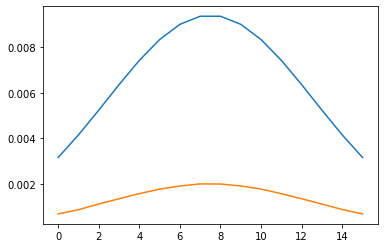

In [10]:
for v in ('d', 'dust_d'):
    d=p.var(v)
    plot(d.mean((0,1)))

### Reading data from a run with many patches

The input file ``rubik_test.nml`` creates snapshots with 3x3x3 patches.  One can still access individual patches one-by-one, but one can also access planes stretching through the model, or produce 1-dimensional averages over planes:

In [44]:
sn=dis.snapshot(0,'rubik_test')
len(sn.patches)

27

Computing and plotting averages over planes perpendicular to direction 2 (z-axis):

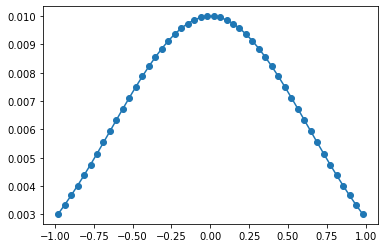

In [53]:
z,f=dse.haver(sn,iv='d',dir=2)
plot(z,f,'-o');

Computing and plotting min and max values over the same planes:

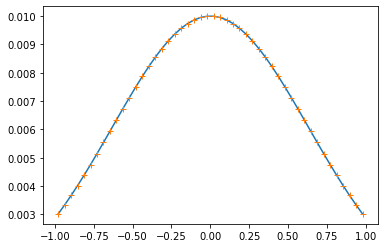

In [50]:
z,f0,f1=dse.hminmax(sn,iv='d',dir=2)
plot(z,f0); plot(z,f1,'+');

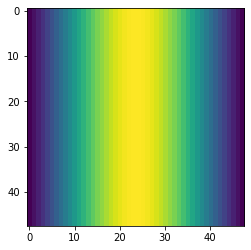

In [69]:
sn=dis.snapshot(1,'rubik_test')
plane=dse.unigrid_plane(sn,x=0.01)
imshow(plane);

The ``dispatch.graphics.uni_grid_plane()`` transposes to Fortran convention, and uses the ``coolwarm``  colorscale by default

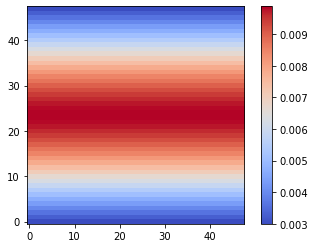

In [71]:
dgr.unigrid_plane(sn,x=1)

Getting a list of patches along a line in the z-direction:

In [89]:
pp=dse.patches_along(sn,dir=2,point=[0.,0.,0.])
for p in pp:
    print('id:{:3d}  z:{:7.3f}'.format(p.id,p.position[2]))

id:  5  z: -0.667
id: 14  z:  0.000
id: 23  z:  0.667


Plotting the density along a line through x,y-index (8,8):

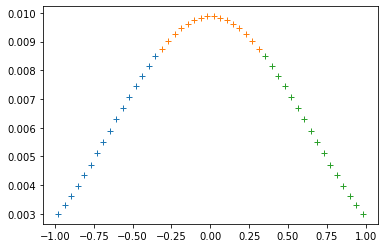

In [91]:
for p in pp:
    plot(p.zi,p.var('d')[8,8,:],'+')